In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn pyarrow joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42
OUTPUT_DIR = Path("hasil")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Library berhasil diimpor.")
print("Folder hasil:", OUTPUT_DIR.resolve())

Library berhasil diimpor.
Folder hasil: C:\Users\User\OneDrive\Documents\Analisis_Clustering_menggunakan_K-Means\hasil


In [8]:
possible_csv = [
    Path(r"C:\Users\User\OneDrive\Documents\Analisis_Clustering_menggunakan_K-Means\archive (6)\global_earthquakes_seismic.csv"),
    Path("global_earthquakes_seismic.csv")
]

csv_path = next((p for p in possible_csv if p.exists()), None)

if csv_path is not None:
    df = pd.read_csv(csv_path)
    print(f"Dataset dibaca dari: {csv_path}")
else:
    possible_zips = [
        Path("dataset/archive (1).zip"),
        Path("archive (1).zip")
    ]
    zip_path = next((p for p in possible_zips if p.exists()), None)

    if zip_path is None:
        # Cari ZIP lain jika nama file berbeda
        candidates = list(Path("dataset").glob("*.zip")) if Path("dataset").exists() else []
        candidates += list(Path(".").glob("*.zip"))
        zip_path = candidates[0] if candidates else None

    if zip_path is None:
        raise FileNotFoundError(
            "Dataset tidak ditemukan. Letakkan archive (1).zip "
            "di folder notebook atau di dalam folder dataset/."
        )

    with zipfile.ZipFile(zip_path, "r") as zf:
        csv_members = [n for n in zf.namelist() if n.lower().endswith(".csv")]
        if not csv_members:
            raise FileNotFoundError("File CSV tidak ditemukan di dalam ZIP.")
        # Pilih CSV yang namanya paling sesuai
        chosen_csv = next(
            (n for n in csv_members if "global_earthquakes_seismic" in Path(n).name.lower()),
            csv_members[0]
        )
        with zf.open(chosen_csv) as f:
            df = pd.read_csv(f)
    print(f"Dataset dibaca dari: {zip_path} -> {chosen_csv}")

print("Dataset berhasil dimuat.")
display(df.head())

Dataset dibaca dari: C:\Users\User\OneDrive\Documents\Analisis_Clustering_menggunakan_K-Means\archive (6)\global_earthquakes_seismic.csv
Dataset berhasil dimuat.


,id,time,latitude,longitude,depth,mag,magType,place,status,tsunami,...,gap,type,title,evidence_span,cot_rationale,magnitude_severity_class,focal_depth_regime,tsunami_hazard_potential,tectonic_boundary_zone,confidence_score
0,us6000u20i,1791884908205,-9.9266,118.8246,35.0,4.5,mb,"71 km SW of Tambolaka, Indonesia",reviewed,0,...,123.0,earthquake,"M 4.5 - 71 km SW of Tambolaka, Indonesia",M: 4.5 (mb) | depth: 35.0km | place: '71 km SW...,"Seismic event 'M 4.5 - 71 km SW of Tambolaka, ...",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98
1,us6000u20g,1791884472899,38.5166,68.8922,10.0,4.7,mb,"9 km NE of Boshkengash, Tajikistan",reviewed,0,...,62.0,earthquake,"M 4.7 - 9 km NE of Boshkengash, Tajikistan",M: 4.7 (mb) | depth: 10.0km | place: '9 km NE ...,"Seismic event 'M 4.7 - 9 km NE of Boshkengash,...",moderate,shallow_crustal,inland_negligible,alpide_himalayan_belt,0.98
2,us6000u207,1791880708325,-28.5560,-12.5205,10.0,5.3,mb,southern Mid-Atlantic Ridge,reviewed,0,...,63.0,earthquake,M 5.3 - southern Mid-Atlantic Ridge,M: 5.3 (mb) | depth: 10.0km | place: 'southern...,Seismic event 'M 5.3 - southern Mid-Atlantic R...,moderate,shallow_crustal,inland_negligible,mid_ocean_ridge_divergent,0.98
3,us6000u1zh,1791873544944,7.7685,-81.4531,10.0,4.7,mb,"14 km WNW of Río Grande, Panama",reviewed,0,...,140.0,earthquake,"M 4.7 - 14 km WNW of Río Grande, Panama",M: 4.7 (mb) | depth: 10.0km | place: '14 km WN...,Seismic event 'M 4.7 - 14 km WNW of Río Grande...,moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98
4,us6000u1zc,1791871284155,19.6853,120.7047,10.0,4.7,mb,"124 km N of Pagudpud, Philippines",reviewed,0,...,132.0,earthquake,"M 4.7 - 124 km N of Pagudpud, Philippines",M: 4.7 (mb) | depth: 10.0km | place: '124 km N...,"Seismic event 'M 4.7 - 124 km N of Pagudpud, P...",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98


In [9]:
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

print("\nNama kolom:")
print(df.columns.tolist())

print("\nInformasi tipe data:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe(include="all").T)

Jumlah baris: 10000
Jumlah kolom: 25

Nama kolom:
['id', 'time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'place', 'status', 'tsunami', 'sig', 'net', 'nst', 'dmin', 'rms', 'gap', 'type', 'title', 'evidence_span', 'cot_rationale', 'magnitude_severity_class', 'focal_depth_regime', 'tsunami_hazard_potential', 'tectonic_boundary_zone', 'confidence_score']

Informasi tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        10000 non-null  object 
 1   time                      10000 non-null  int64  
 2   latitude                  10000 non-null  float64
 3   longitude                 10000 non-null  float64
 4   depth                     10000 non-null  float64
 5   mag                       10000 non-null  float64
 6   magType                   10000 non-null  object 
 7   place

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,10000,10000,us6000u20i,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time,10000.0,NaN,NaN,NaN,1771917356330.238281,11690270724.464771,1753890068273.0,1760858167777.75,1772139731421.5,1782527070837.75,1791884908205.0
latitude,10000.0,NaN,NaN,NaN,7.828576,31.909441,-67.4686,-15.4493,5.19465,38.385925,85.0643
longitude,10000.0,NaN,NaN,NaN,61.65019,116.440894,-179.997,-32.6293,125.0271,152.264525,179.9899
depth,10000.0,NaN,NaN,NaN,56.165777,101.577053,0.0,10.0,11.0,56.99325,669.556
mag,10000.0,NaN,NaN,NaN,4.812037,0.367266,4.5,4.5,4.7,5.0,7.8
magType,10000,8,mb,8060,NaN,NaN,NaN,NaN,NaN,NaN,NaN
place,10000,6821,South Sandwich Islands region,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,10000,1,reviewed,10000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tsunami,10000.0,NaN,NaN,NaN,0.0084,0.09127,0.0,0.0,0.0,0.0,1.0


In [10]:
candidate_features = [
    "latitude",
    "longitude",
    "depth",
    "mag",
    "tsunami",
    "sig",
    "nst",
    "dmin",
    "rms",
    "gap",
    "confidence_score"
]

missing_features = [col for col in candidate_features if col not in df.columns]
if missing_features:
    raise ValueError(
        "Kolom fitur berikut tidak ditemukan pada dataset: "
        + ", ".join(missing_features)
    )

features = candidate_features.copy()
data = df[features].copy()

# Pastikan seluruh fitur benar-benar numerik
data = data.apply(pd.to_numeric, errors="coerce")
data = data.replace([np.inf, -np.inf], np.nan)

print("Fitur yang digunakan:")
print(features)
print("\nUkuran data fitur:", data.shape)
display(data.head())

Fitur yang digunakan:
['latitude', 'longitude', 'depth', 'mag', 'tsunami', 'sig', 'nst', 'dmin', 'rms', 'gap', 'confidence_score']

Ukuran data fitur: (10000, 11)


,latitude,longitude,depth,mag,tsunami,sig,nst,dmin,rms,gap,confidence_score
0,-9.9266,118.8246,35.0,4.5,0,312,28,4.966,0.67,123.0,0.98
1,38.5166,68.8922,10.0,4.7,0,340,64,1.821,0.70,62.0,0.98
2,-28.5560,-12.5205,10.0,5.3,0,432,37,27.968,1.03,63.0,0.98
3,7.7685,-81.4531,10.0,4.7,0,340,37,2.117,0.80,140.0,0.98
4,19.6853,120.7047,10.0,4.7,0,340,42,3.136,0.95,132.0,0.98


In [11]:
print("Missing values per fitur:")
display(data.isna().sum().to_frame("jumlah_missing"))

print("Total missing values:", int(data.isna().sum().sum()))
print("Jumlah baris duplikat:", int(df.duplicated().sum()))

Missing values per fitur:


,jumlah_missing
latitude,0
longitude,0
depth,0
mag,0
tsunami,0
sig,0
nst,0
dmin,0
rms,0
gap,0


Total missing values: 0
Jumlah baris duplikat: 0


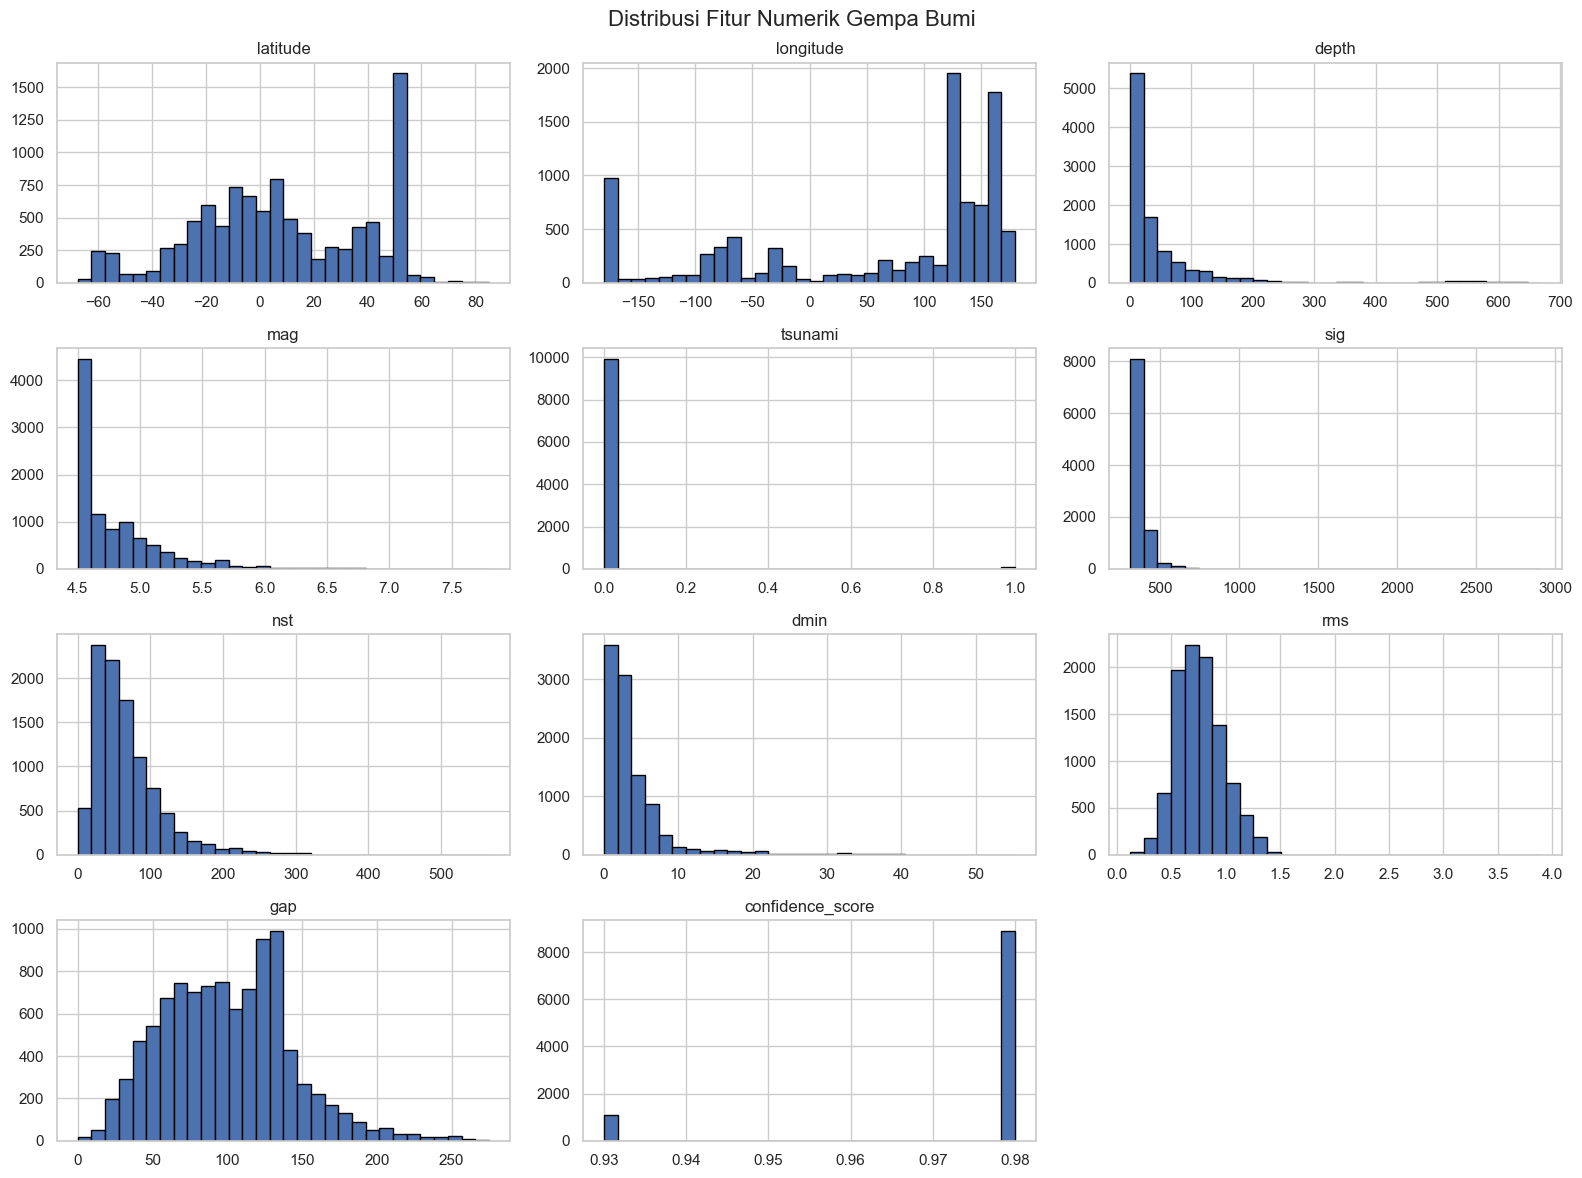

In [12]:
data.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)
plt.suptitle("Distribusi Fitur Numerik Gempa Bumi", fontsize=16)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_histogram_distribusi.png", dpi=300, bbox_inches="tight")
plt.show()

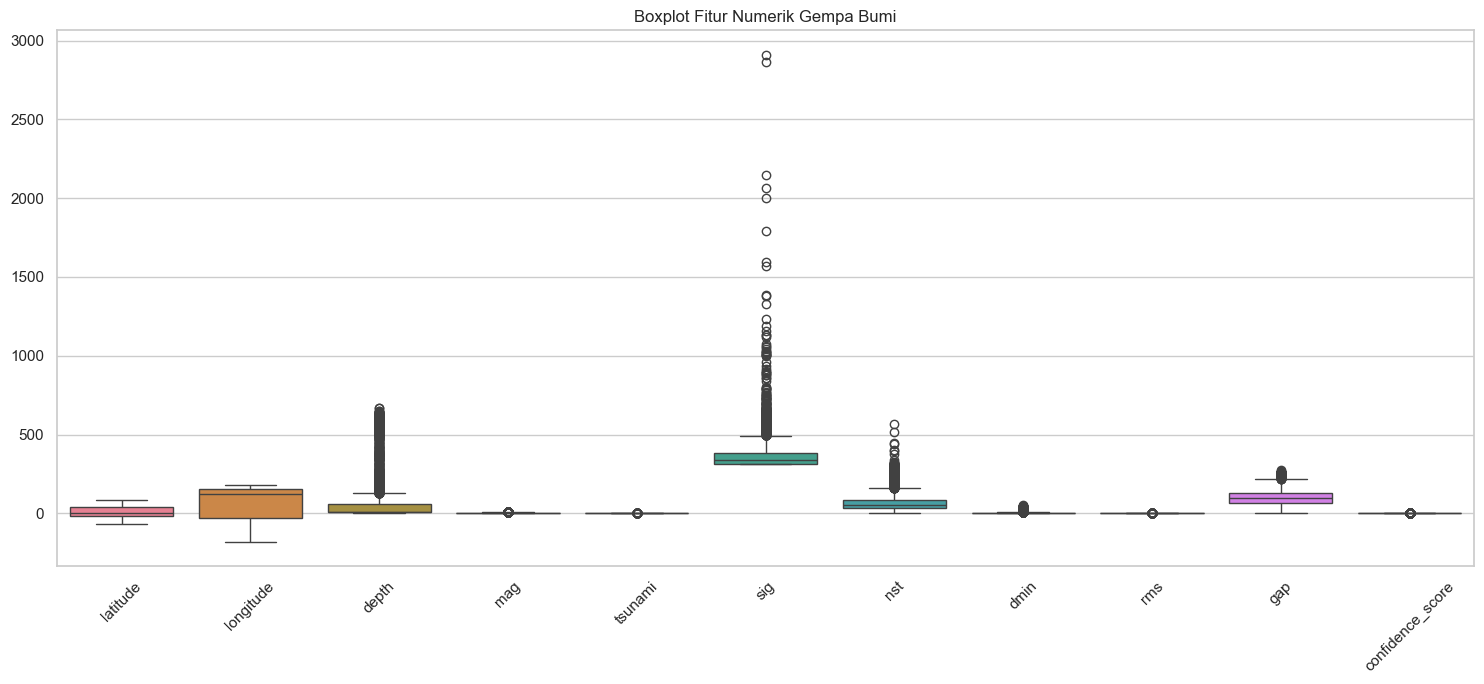

In [13]:
fig, ax = plt.subplots(figsize=(15, 7))
sns.boxplot(data=data, ax=ax)
ax.set_title("Boxplot Fitur Numerik Gempa Bumi")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_boxplot_outlier.png", dpi=300, bbox_inches="tight")
plt.show()

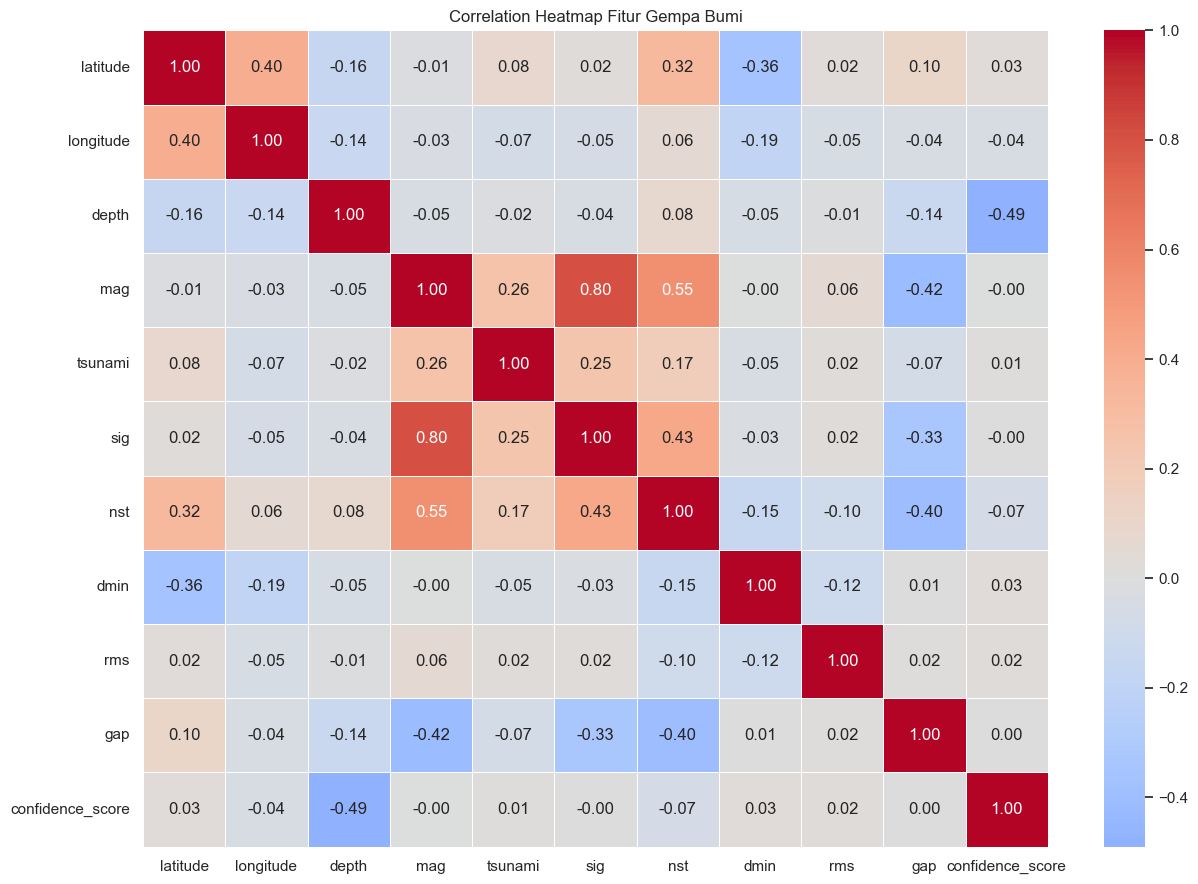

,latitude,longitude,depth,mag,tsunami,sig,nst,dmin,rms,gap,confidence_score
latitude,1.000,0.401,-0.161,-0.013,0.085,0.017,0.324,-0.362,0.023,0.104,0.028
longitude,0.401,1.000,-0.145,-0.034,-0.071,-0.054,0.062,-0.188,-0.053,-0.038,-0.038
depth,-0.161,-0.145,1.000,-0.046,-0.020,-0.041,0.077,-0.052,-0.012,-0.139,-0.490
mag,-0.013,-0.034,-0.046,1.000,0.257,0.805,0.550,-0.005,0.059,-0.418,-0.003
tsunami,0.085,-0.071,-0.020,0.257,1.000,0.246,0.174,-0.046,0.021,-0.074,0.011
sig,0.017,-0.054,-0.041,0.805,0.246,1.000,0.425,-0.026,0.021,-0.328,-0.000
nst,0.324,0.062,0.077,0.550,0.174,0.425,1.000,-0.152,-0.100,-0.404,-0.069
dmin,-0.362,-0.188,-0.052,-0.005,-0.046,-0.026,-0.152,1.000,-0.117,0.005,0.028
rms,0.023,-0.053,-0.012,0.059,0.021,0.021,-0.100,-0.117,1.000,0.016,0.022
gap,0.104,-0.038,-0.139,-0.418,-0.074,-0.328,-0.404,0.005,0.016,1.000,0.005


In [14]:
corr = data.corr(numeric_only=True)

plt.figure(figsize=(13, 9))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.4
)
plt.title("Correlation Heatmap Fitur Gempa Bumi")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

display(corr.round(3))

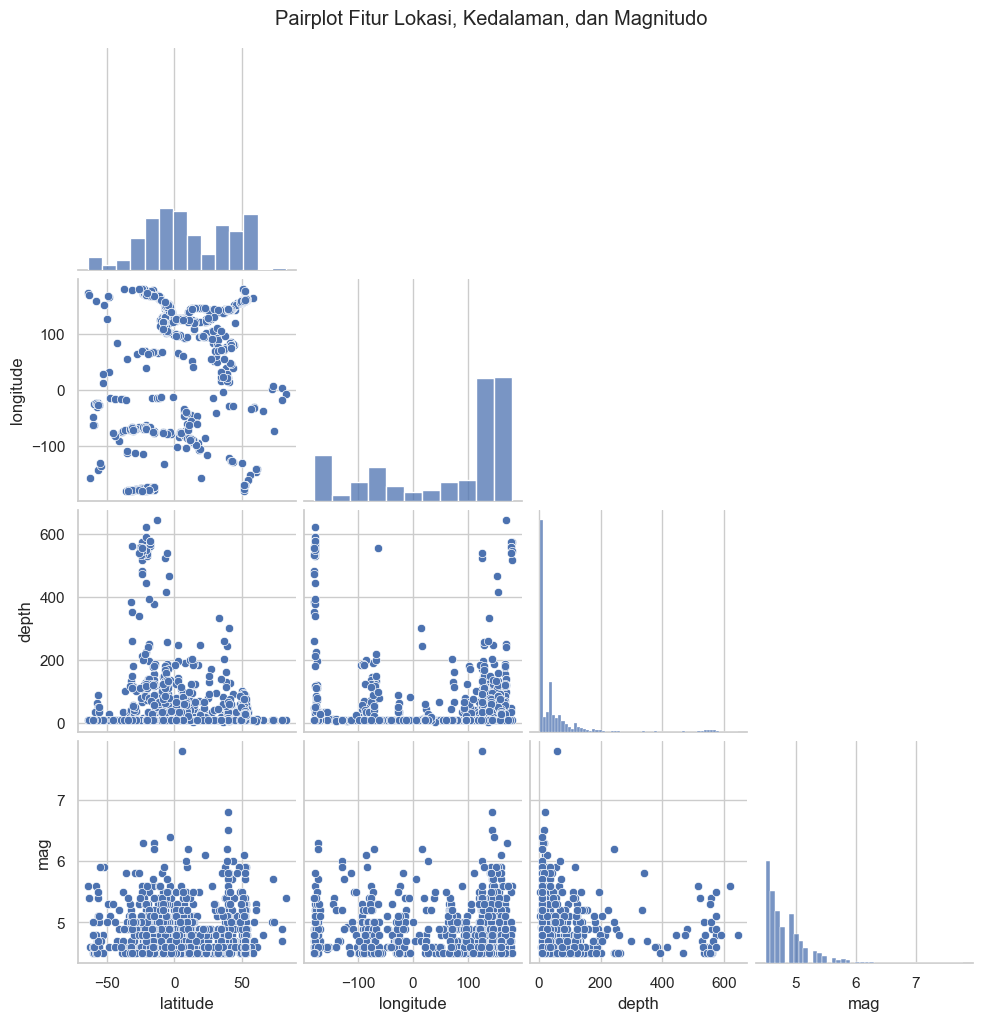

In [15]:
pair_features = ["latitude", "longitude", "depth", "mag"]
pair_data = data[pair_features].dropna()

# Ambil sampel maksimal 1.000 baris agar grafik tidak terlalu berat
pair_sample = pair_data.sample(
    n=min(1000, len(pair_data)),
    random_state=RANDOM_STATE
)

g = sns.pairplot(pair_sample, diag_kind="hist", corner=True)
g.fig.suptitle("Pairplot Fitur Lokasi, Kedalaman, dan Magnitudo", y=1.02)
g.savefig(OUTPUT_DIR / "04_pairplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
# Hilangkan duplikasi berdasarkan seluruh kolom dataset
df_clean = df.drop_duplicates().reset_index(drop=True)

# Ambil fitur dari data yang sudah bebas duplikasi
X = df_clean[features].copy()
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

# Isi missing value menggunakan median tiap fitur
medians = X.median()
X = X.fillna(medians)

# Jika suatu kolom seluruhnya kosong, median tetap NaN; hentikan dengan pesan jelas
if X.isna().any().any():
    bad_cols = X.columns[X.isna().any()].tolist()
    raise ValueError(f"Fitur seluruhnya kosong/tidak dapat diolah: {bad_cols}")

# Standarisasi
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=X.index)

print("Jumlah data setelah hapus duplikat:", len(df_clean))
print("Missing values setelah imputasi:", int(X.isna().sum().sum()))
print("Standarisasi selesai.")
display(X_scaled_df.head())

Jumlah data setelah hapus duplikat: 10000
Missing values setelah imputasi: 0
Standarisasi selesai.


,latitude,longitude,depth,mag,tsunami,sig,nst,dmin,rms,gap,confidence_score
0,-0.556452,0.491041,-0.208382,-0.849663,-0.092039,-0.575155,-0.827727,0.159226,-0.420492,0.537484,0.351741
1,0.961770,0.062198,-0.454513,-0.305071,-0.092039,-0.256652,-0.059374,-0.438362,-0.284073,-0.888397,0.351741
2,-1.140302,-0.637013,-0.454513,1.328705,-0.092039,0.789858,-0.635639,4.529887,1.216533,-0.865022,0.351741
3,-0.001883,-1.229039,-0.454513,-0.305071,-0.092039,-0.256652,-0.635639,-0.382119,0.170656,0.934860,0.351741
4,0.371593,0.507188,-0.454513,-0.305071,-0.092039,-0.256652,-0.528924,-0.188496,0.852750,0.747860,0.351741


In [17]:
# Simpan data hasil preprocessing
X.to_csv(OUTPUT_DIR / "data_sebelum_standarisasi.csv", index=False)
X_scaled_df.to_csv(OUTPUT_DIR / "data_preprocessing.csv", index=False)

# Simpan scaler dan daftar fitur untuk penggunaan ulang
joblib.dump(scaler, OUTPUT_DIR / "standard_scaler.joblib")
with open(OUTPUT_DIR / "fitur_clustering.json", "w", encoding="utf-8") as f:
    import json
    json.dump(features, f, ensure_ascii=False, indent=2)

print("Data preprocessing dan scaler berhasil disimpan.")

Data preprocessing dan scaler berhasil disimpan.


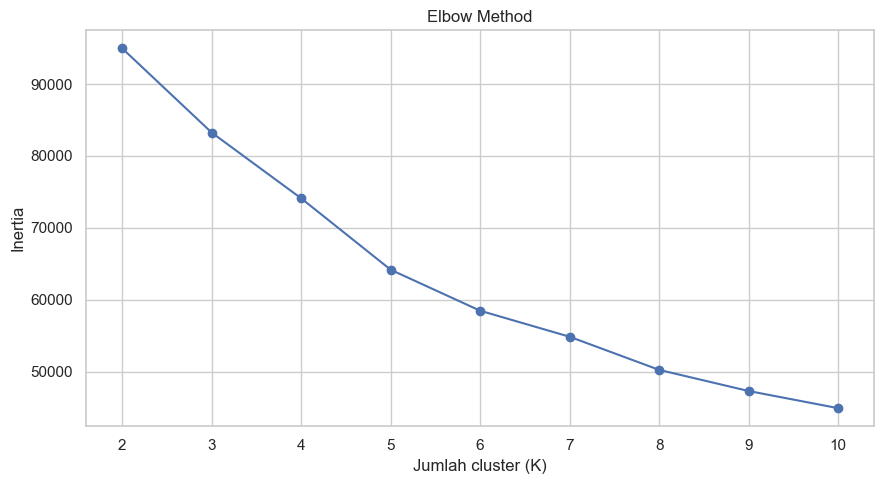

,K,Inertia
0,2,94966.063482
1,3,83244.204130
2,4,74096.181002
3,5,64161.773098
4,6,58459.306932
5,7,54837.106773
6,8,50227.821119
7,9,47288.304976
8,10,44901.940141


In [18]:
k_values = list(range(2, 11))
inertias = []

for k in k_values:
    km = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    km.fit(X_scaled)
    inertias.append(km.inertia_)

elbow_df = pd.DataFrame({"K": k_values, "Inertia": inertias})

plt.figure(figsize=(9, 5))
plt.plot(k_values, inertias, marker="o")
plt.xticks(k_values)
plt.xlabel("Jumlah cluster (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_elbow_method.png", dpi=300, bbox_inches="tight")
plt.show()

display(elbow_df)

K=2: Silhouette Score=0.2425
K=3: Silhouette Score=0.2732
K=4: Silhouette Score=0.2209
K=5: Silhouette Score=0.2237
K=6: Silhouette Score=0.2199
K=7: Silhouette Score=0.1566
K=8: Silhouette Score=0.1784
K=9: Silhouette Score=0.1847
K=10: Silhouette Score=0.1821


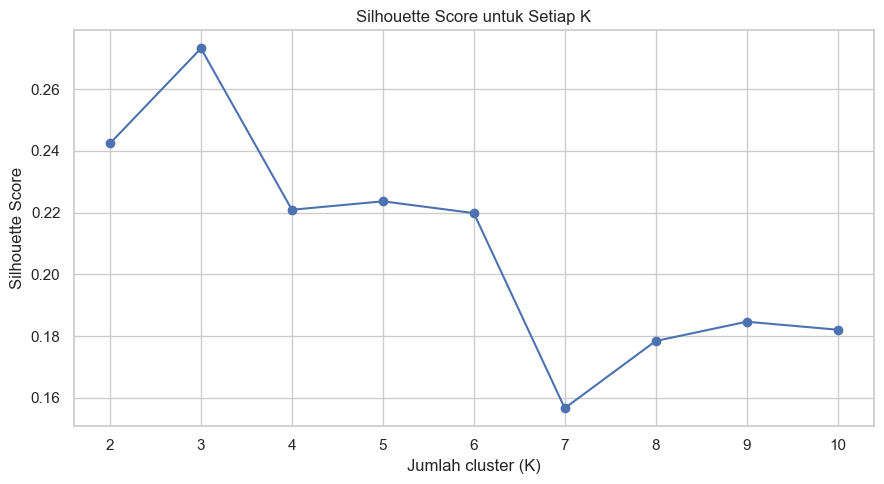

,K,Silhouette Score
0,2,0.242454
1,3,0.273242
2,4,0.220944
3,5,0.223682
4,6,0.219862
5,7,0.156638
6,8,0.178414
7,9,0.184661
8,10,0.182070


In [19]:
silhouette_scores = []

# Silhouette dihitung pada sampel maksimal 3.000 baris agar waktu komputasi terkendali.
sil_sample_size = min(3000, len(X_scaled))

for k in k_values:
    km = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    labels_k = km.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels_k,
        sample_size=sil_sample_size,
        random_state=RANDOM_STATE
    )
    silhouette_scores.append(score)
    print(f"K={k}: Silhouette Score={score:.4f}")

silhouette_df = pd.DataFrame({
    "K": k_values,
    "Silhouette Score": silhouette_scores
})

plt.figure(figsize=(9, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xticks(k_values)
plt.xlabel("Jumlah cluster (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score untuk Setiap K")
plt.grid(True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_silhouette_score.png", dpi=300, bbox_inches="tight")
plt.show()

display(silhouette_df)

In [20]:
# Rekomendasi awal berdasarkan Silhouette Score tertinggi
best_k_silhouette = int(
    silhouette_df.loc[silhouette_df["Silhouette Score"].idxmax(), "K"]
)

print("K dengan Silhouette Score tertinggi:", best_k_silhouette)

# Ubah nilai ini jika hasil Elbow Method menunjukkan pilihan K lain yang lebih masuk akal.
# Nilai default menggunakan rekomendasi Silhouette Score.
K_FINAL = best_k_silhouette

kmeans = KMeans(
    n_clusters=K_FINAL,
    random_state=RANDOM_STATE,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

hasil = df_clean.copy()
hasil["cluster"] = cluster_labels

print("K final:", K_FINAL)
print("Clustering selesai.")
display(hasil.head())

K dengan Silhouette Score tertinggi: 3
K final: 3
Clustering selesai.


,id,time,latitude,longitude,depth,mag,magType,place,status,tsunami,...,type,title,evidence_span,cot_rationale,magnitude_severity_class,focal_depth_regime,tsunami_hazard_potential,tectonic_boundary_zone,confidence_score,cluster
0,us6000u20i,1791884908205,-9.9266,118.8246,35.0,4.5,mb,"71 km SW of Tambolaka, Indonesia",reviewed,0,...,earthquake,"M 4.5 - 71 km SW of Tambolaka, Indonesia",M: 4.5 (mb) | depth: 35.0km | place: '71 km SW...,"Seismic event 'M 4.5 - 71 km SW of Tambolaka, ...",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98,0
1,us6000u20g,1791884472899,38.5166,68.8922,10.0,4.7,mb,"9 km NE of Boshkengash, Tajikistan",reviewed,0,...,earthquake,"M 4.7 - 9 km NE of Boshkengash, Tajikistan",M: 4.7 (mb) | depth: 10.0km | place: '9 km NE ...,"Seismic event 'M 4.7 - 9 km NE of Boshkengash,...",moderate,shallow_crustal,inland_negligible,alpide_himalayan_belt,0.98,0
2,us6000u207,1791880708325,-28.5560,-12.5205,10.0,5.3,mb,southern Mid-Atlantic Ridge,reviewed,0,...,earthquake,M 5.3 - southern Mid-Atlantic Ridge,M: 5.3 (mb) | depth: 10.0km | place: 'southern...,Seismic event 'M 5.3 - southern Mid-Atlantic R...,moderate,shallow_crustal,inland_negligible,mid_ocean_ridge_divergent,0.98,0
3,us6000u1zh,1791873544944,7.7685,-81.4531,10.0,4.7,mb,"14 km WNW of Río Grande, Panama",reviewed,0,...,earthquake,"M 4.7 - 14 km WNW of Río Grande, Panama",M: 4.7 (mb) | depth: 10.0km | place: '14 km WN...,Seismic event 'M 4.7 - 14 km WNW of Río Grande...,moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98,0
4,us6000u1zc,1791871284155,19.6853,120.7047,10.0,4.7,mb,"124 km N of Pagudpud, Philippines",reviewed,0,...,earthquake,"M 4.7 - 124 km N of Pagudpud, Philippines",M: 4.7 (mb) | depth: 10.0km | place: '124 km N...,"Seismic event 'M 4.7 - 124 km N of Pagudpud, P...",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98,0


In [21]:
final_inertia = float(kmeans.inertia_)
final_silhouette = float(
    silhouette_score(
        X_scaled,
        cluster_labels,
        sample_size=min(3000, len(X_scaled)),
        random_state=RANDOM_STATE
    )
)

print("HASIL EVALUASI K-MEANS")
print("=" * 40)
print("Jumlah cluster:", K_FINAL)
print(f"Inertia: {final_inertia:.4f}")
print(f"Silhouette Score: {final_silhouette:.4f}")

HASIL EVALUASI K-MEANS
Jumlah cluster: 3
Inertia: 83244.2041
Silhouette Score: 0.2732


In [22]:
cluster_mean = hasil.groupby("cluster")[features].mean().round(3)
cluster_median = hasil.groupby("cluster")[features].median().round(3)
cluster_count = hasil["cluster"].value_counts().sort_index().rename("jumlah_data")

print("Rata-rata fitur per cluster:")
display(cluster_mean)

print("Median fitur per cluster:")
display(cluster_median)

print("Jumlah anggota per cluster:")
display(cluster_count.to_frame())

Rata-rata fitur per cluster:


,latitude,longitude,depth,mag,tsunami,sig,nst,dmin,rms,gap,confidence_score
cluster,,,,,,,,,,,
0,6.852,64.106,31.302,4.687,0.000,339.086,50.475,4.361,0.766,109.829,0.980
1,15.437,61.782,35.461,5.357,0.047,465.376,128.848,3.418,0.759,60.762,0.978
2,2.010,46.509,239.404,4.733,0.000,346.487,70.066,3.807,0.746,100.901,0.935


Median fitur per cluster:


,latitude,longitude,depth,mag,tsunami,sig,nst,dmin,rms,gap,confidence_score
cluster,,,,,,,,,,,
0,4.962,124.124,10.00,4.6,0.0,326.0,46.0,2.473,0.75,110.0,0.98
1,14.243,124.106,12.00,5.2,0.0,432.0,115.0,2.093,0.73,52.0,0.98
2,-5.674,126.722,139.06,4.6,0.0,326.0,61.0,3.489,0.72,102.0,0.93


Jumlah anggota per cluster:


,jumlah_data
cluster,
0,7050
1,1791
2,1159


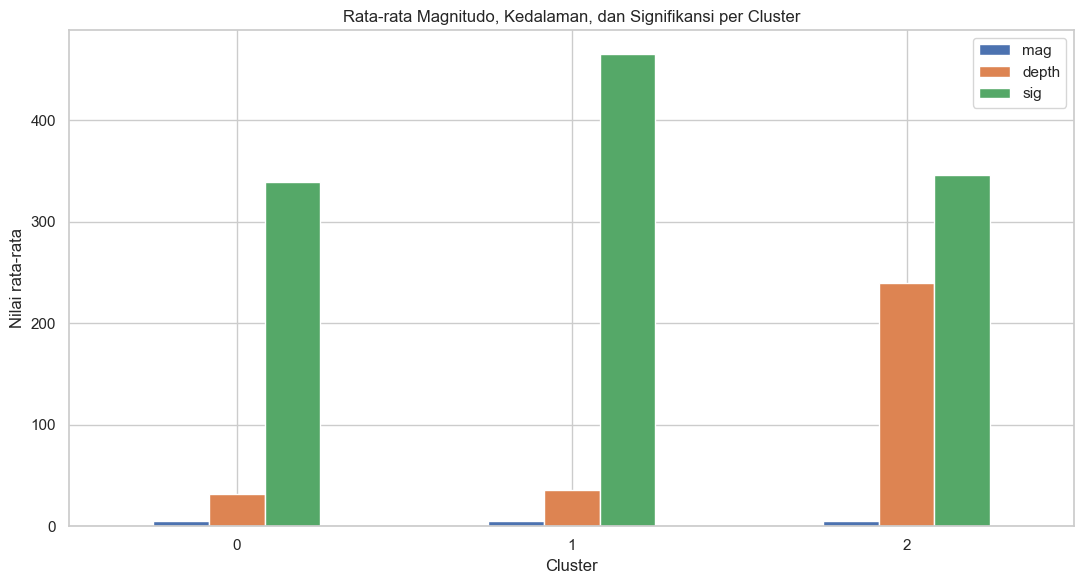

In [23]:
# Grafik perbandingan rata-rata beberapa fitur penting
summary_plot = cluster_mean[["mag", "depth", "sig"]]

ax = summary_plot.plot(kind="bar", figsize=(11, 6))
ax.set_title("Rata-rata Magnitudo, Kedalaman, dan Signifikansi per Cluster")
ax.set_xlabel("Cluster")
ax.set_ylabel("Nilai rata-rata")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_karakteristik_cluster.png", dpi=300, bbox_inches="tight")
plt.show()

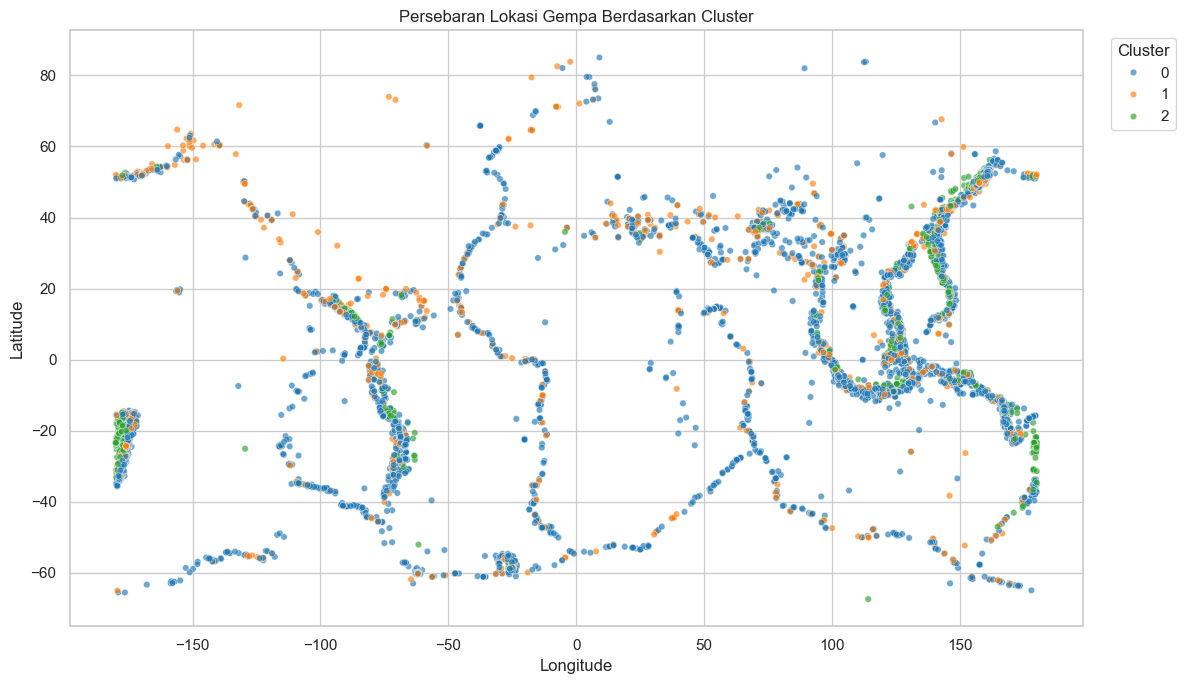

In [24]:
plot_df = hasil[["latitude", "longitude", "cluster"]].copy()

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=plot_df,
    x="longitude",
    y="latitude",
    hue="cluster",
    palette="tab10",
    s=22,
    alpha=0.65
)
plt.title("Persebaran Lokasi Gempa Berdasarkan Cluster")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "08_scatter_lokasi_cluster.png", dpi=300, bbox_inches="tight")
plt.show()

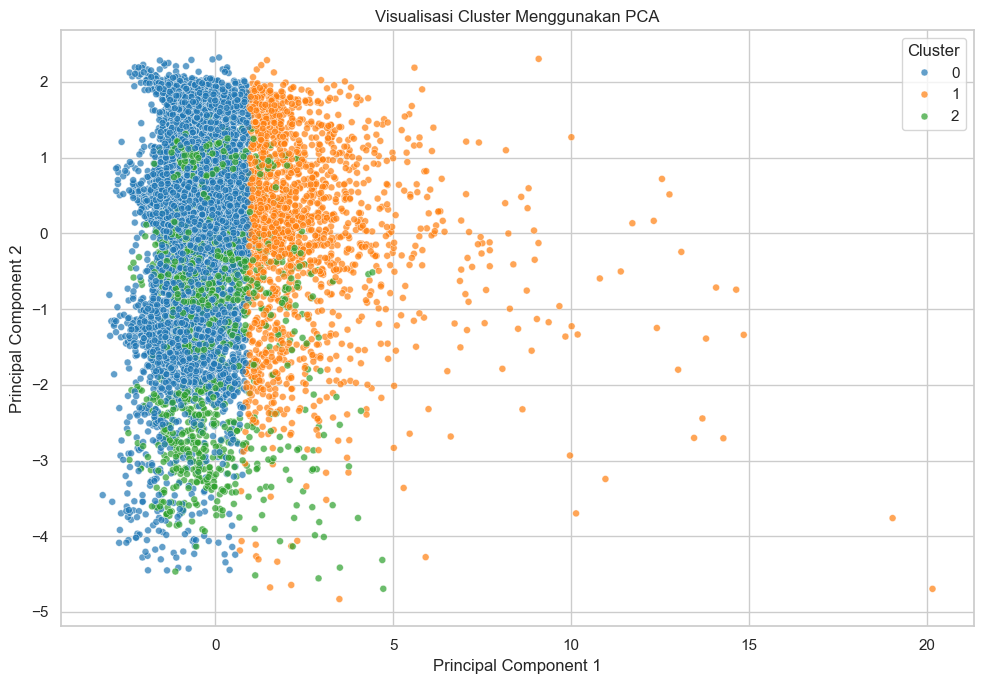

Total variasi yang dijelaskan dua komponen PCA: 39.70%


In [25]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["cluster"] = cluster_labels

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    alpha=0.7,
    s=25
)
plt.title("Visualisasi Cluster Menggunakan PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "09_pca_cluster.png", dpi=300, bbox_inches="tight")
plt.show()

explained = pca.explained_variance_ratio_.sum() * 100
print(f"Total variasi yang dijelaskan dua komponen PCA: {explained:.2f}%")

In [26]:
# Hasil data lengkap dengan label cluster
hasil.to_csv(OUTPUT_DIR / "hasil_clustering_gempa.csv", index=False)

# Ringkasan cluster
cluster_mean.to_csv(OUTPUT_DIR / "ringkasan_cluster_mean.csv")
cluster_median.to_csv(OUTPUT_DIR / "ringkasan_cluster_median.csv")
cluster_count.to_csv(OUTPUT_DIR / "jumlah_anggota_cluster.csv")

# Evaluasi model
evaluasi = pd.DataFrame({
    "metrik": ["jumlah_cluster", "inertia", "silhouette_score"],
    "nilai": [K_FINAL, final_inertia, final_silhouette]
})
evaluasi.to_csv(OUTPUT_DIR / "evaluasi_kmeans.csv", index=False)

# Simpan model dan komponen PCA agar dapat digunakan kembali
joblib.dump(kmeans, OUTPUT_DIR / "model_kmeans.joblib")
joblib.dump(pca, OUTPUT_DIR / "model_pca.joblib")

# Simpan hasil pencarian K
elbow_df.to_csv(OUTPUT_DIR / "hasil_elbow.csv", index=False)
silhouette_df.to_csv(OUTPUT_DIR / "hasil_silhouette.csv", index=False)

print("Semua hasil berhasil disimpan di:", OUTPUT_DIR.resolve())
print("\nFile yang tersimpan:")
for file in sorted(OUTPUT_DIR.iterdir()):
    print("-", file.name)

Semua hasil berhasil disimpan di: C:\Users\User\OneDrive\Documents\Analisis_Clustering_menggunakan_K-Means\hasil

File yang tersimpan:
- 01_histogram_distribusi.png
- 02_boxplot_outlier.png
- 03_correlation_heatmap.png
- 04_pairplot.png
- 05_elbow_method.png
- 06_silhouette_score.png
- 07_karakteristik_cluster.png
- 08_scatter_lokasi_cluster.png
- 09_pca_cluster.png
- data_preprocessing.csv
- data_sebelum_standarisasi.csv
- evaluasi_kmeans.csv
- fitur_clustering.json
- hasil_clustering_gempa.csv
- hasil_elbow.csv
- hasil_silhouette.csv
- jumlah_anggota_cluster.csv
- model_kmeans.joblib
- model_pca.joblib
- ringkasan_cluster_mean.csv
- ringkasan_cluster_median.csv
- standard_scaler.joblib


In [27]:
print("=" * 65)
print("KESIMPULAN PRAKTIKUM K-MEANS CLUSTERING GEMPA BUMI")
print("=" * 65)

print(f"Jumlah data yang dianalisis : {len(hasil)}")
print(f"Jumlah fitur clustering     : {len(features)}")
print(f"Jumlah cluster akhir        : {K_FINAL}")
print(f"Inertia                     : {final_inertia:.4f}")
print(f"Silhouette Score            : {final_silhouette:.4f}")

print("\nJumlah anggota dan rata-rata karakteristik:")
for cid in cluster_mean.index:
    n_data = int(cluster_count.loc[cid])
    print(
        f"Cluster {cid}: {n_data} data | "
        f"rata-rata magnitudo={cluster_mean.loc[cid, 'mag']:.2f} | "
        f"rata-rata kedalaman={cluster_mean.loc[cid, 'depth']:.2f} km"
    )

print("\nCatatan:")
print(
    "Interpretasi akhir harus melihat tabel rata-rata/median setiap cluster, "
    "grafik Elbow, dan Silhouette Score. Cluster merupakan kelompok kemiripan "
    "data, bukan klasifikasi resmi tingkat bahaya gempa."
)

KESIMPULAN PRAKTIKUM K-MEANS CLUSTERING GEMPA BUMI
Jumlah data yang dianalisis : 10000
Jumlah fitur clustering     : 11
Jumlah cluster akhir        : 3
Inertia                     : 83244.2041
Silhouette Score            : 0.2732

Jumlah anggota dan rata-rata karakteristik:
Cluster 0: 7050 data | rata-rata magnitudo=4.69 | rata-rata kedalaman=31.30 km
Cluster 1: 1791 data | rata-rata magnitudo=5.36 | rata-rata kedalaman=35.46 km
Cluster 2: 1159 data | rata-rata magnitudo=4.73 | rata-rata kedalaman=239.40 km

Catatan:
Interpretasi akhir harus melihat tabel rata-rata/median setiap cluster, grafik Elbow, dan Silhouette Score. Cluster merupakan kelompok kemiripan data, bukan klasifikasi resmi tingkat bahaya gempa.
